# Cerro Bravo study-site application

This notebook applies `unsatstab` to 105 mapped slope units from Cerro Bravo, a volcanic hill in the Colombian Andes. The site and the related probabilistic rainfall–landslide framework are described by Ruiz, Montoya-Araque and Gamboa in a manuscript currently under review in *Natural Hazards*. The study discusses the shallow landslide cluster of June 2024, TRIGRS simulations, uncertain soil and depth properties, and comparison with a mapped landslide inventory.

Here we retain a deterministic application with shared material `n4n6-Hi`: uniform rainfall and a single asymmetric peak both supply 78 mm over one hour. Each water table starts at its unit's maximum column depth. Five snapshots show base FS and water-table rise. These settings belong to this notebook; they are not asserted to reproduce the paper's complete calibration or stochastic ensemble.

The notebook is organized as a validation case study because its geometry belongs to a real study site. The calculations below do not load an observed inventory or calculate agreement with observations, so they do not independently validate `unsatstab`. In particular, the manuscript's TRIGRS-based validation statistics cannot be transferred to this implementation. The [validation status](/unsatstab/verification/#scope) explains the distinction.

The example uses the default `srivastava_yeh` equation set. Units do not route runoff or groundwater to their neighbours. See the [equation comparison](/unsatstab/fundamentals/#pressure-and-water-content-equation-sets).

**Reference:** Ruiz, D. F., Montoya-Araque, E. A., & Gamboa, M. F. (202X). *Probabilistic modeling of rainfall thresholds and landslide hazard: A physics-based numerical approach*. Manuscript submitted to *Natural Hazards*, currently under review.

## Inspect the inputs

`ruiz_etal_slope_units.gpkg` contains geometry and the five required SU fields. `ruiz_etal_material_properties.csv` contains hydraulic and strength defaults, background infiltration, and drainage settings, keyed by `material_id`.

Both files use material `n4n6-Hi`. In the GeoPackage, `initial_water_table_depth_m` equals `maximum_depth_m` for every unit. No initial water table adjustment is needed. The depth values and representative material properties define the example; they are not a mapped slip surface or a calibrated prediction.

`materials_from_dataframe` builds the dictionary of hydraulic, strength, and boundary objects. See [spatial tables and material mappings](/unsatstab/inputs-outputs/#spatial-tables) for the schema and override rules.


In [15]:
%matplotlib inline
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import tol_colors as tc
import numpy as np
import pandas as pd
from IPython.display import display
import unsatstab as us

mpl.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 8.5,
    "mathtext.fontset": "dejavuserif",
    "axes.titlesize": 9,
    "axes.labelsize": 8.5,
    "axes.linewidth": 1.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.unicode_minus": False,
    "axes.grid": False,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "legend.frameon": False,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
})
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "unsatstab").is_dir())

data_dir = ROOT / "docs" / "validation" / "data"
slope_units = us.read_slope_units(data_dir / "ruiz_etal_slope_units.gpkg", layer="slope_units")
material_table = pd.read_csv(data_dir / "ruiz_etal_material_properties.csv")
materials = us.materials_from_dataframe(material_table)

print(f"Package version: {us.__version__}")
print(f"Slope units: {len(slope_units)}")
print(f"CRS: {slope_units.crs.name}")
display(slope_units.drop(columns="geometry").head())
display(material_table)
print("Material mapping keys:", list(materials))
assert set(slope_units["material_id"]) == {"n4n6-Hi"}
assert set(materials) == {"n4n6-Hi"}
assert np.allclose(slope_units["initial_water_table_depth_m"], slope_units["maximum_depth_m"])


Package version: 1.0.0
Slope units: 105
CRS: MAGNA_SIRGAS_Origen_Nacional


,su_id,slope_angle_deg,material_id,maximum_depth_m,initial_water_table_depth_m
0,1,41.015961,n4n6-Hi,2.549533,2.549533
1,2,44.008621,n4n6-Hi,3.063241,3.063241
2,4,39.017697,n4n6-Hi,1.786165,1.786165
3,6,42.669580,n4n6-Hi,3.469650,3.469650
4,7,44.894767,n4n6-Hi,3.368855,3.368855


,material_id,saturated_hydraulic_conductivity_m_s,alpha_m_inv,theta_s,theta_r,cohesion_pa,friction_angle_deg,unit_weight_soil_n_m3,unit_weight_water_n_m3,long_term_infiltration_m_s,boundary,drainage_efficiency
0,n4n6-Hi,0.0001,0.45,0.3,0.1,10000.0,39.2,19000.0,9810.0,1.000000e-07,finite,0.03


Material mapping keys: ['n4n6-Hi']


## Define the two rainfall histories

Uniform rainfall is 78 mm/h for one hour. The nonconstant history rises rapidly to 216 mm/h between minutes 15 and 20, then decreases over the remaining 40 minutes. Each intensity is held over a five-minute interval. The intensities sum to 936 mm/h; multiplying by 5/60 h gives the same 78 mm as the uniform event.

The material's saturated conductivity is 360 mm/h. Every rainfall rate is below this cap, so gross rainfall and effective infiltration both total 78 mm. The higher early input changes the timing of infiltration without changing its total.

The five map times are 0, 15, 30, 45 and 60 minutes. Storage integration uses intervals no longer than one minute, independently of these output times. A separate check below compares this with a 30-second step. Rainfall ends at 60 minutes, but basal transfer and the column response can continue after the plotted window.

,History,Duration [h],Rainfall [mm]
0,Uniform,1.0,78.0
1,Nonconstant,1.0,78.0


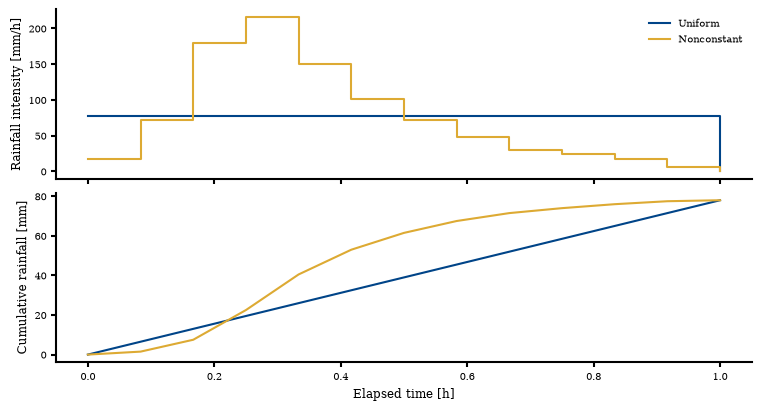

In [27]:
rainfall_histories = {
    "Uniform": us.RainfallSeries.constant(intensity=78.0, duration=1.0),
    "Nonconstant": us.RainfallSeries.from_intervals(
        intensities = np.array([
            18.0, 72.0, 180.0, 216.0, 150.0, 102.0,
            72.0, 48.0, 30.0, 24.0, 18.0, 6.0,
        ]),  # mm/h
        durations = np.full(12, 5.0 / 60.0)  # convert minutes to hours
    ),
}
output_times = np.array([0.0, 15.0, 30.0, 40.0, 50.0, 60.0]) / 60.0  # convert minutes to hours
rainfall_rows = []
for name, forcing in rainfall_histories.items():
    rates_mm_h = forcing.fluxes * 3.6e6  # convert m/s to mm/h
    total_mm = np.dot(np.diff(forcing.breakpoints), rates_mm_h)
    assert np.isclose(forcing.duration, 1.0)
    assert np.isclose(total_mm, 78.0)
    assert forcing.max_flux <= materials["n4n6-Hi"]["hydro"].saturated_hydraulic_conductivity
    rainfall_rows.append({"History": name, "Duration [h]": forcing.duration,
                          "Rainfall [mm]": total_mm})
display(pd.DataFrame(rainfall_rows))

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(7.5, 4.0), constrained_layout=True)
for name, color in zip(rainfall_histories, [tc.colorsets["high_contrast"].blue, tc.colorsets["high_contrast"].yellow]):
    forcing = rainfall_histories[name]
    rates_mm_h = forcing.fluxes * 3.6e6  # convert m/s to mm/h
    cumulative_mm = np.r_[0.0, np.cumsum(np.diff(forcing.breakpoints) * rates_mm_h)]
    axes[0].step(forcing.breakpoints, np.r_[rates_mm_h, 0.0],
                 where="post", color=color, label=name)
    axes[1].plot(forcing.breakpoints, cumulative_mm, color=color)
axes[0].set_ylabel("Rainfall intensity [mm/h]")
axes[0].legend()
axes[1].set(xlabel="Elapsed time [h]", ylabel="Cumulative rainfall [mm]")
plt.show()


## Run all columns for both histories

The same units, material mapping, initial conditions, equation set, and numerical controls are used in both runs. Only rainfall timing changes. Each unit computes hydraulic and stability profiles throughout its complete column.

With no separate observation depth supplied, the extracted pressure and FS series correspond to each unit's base. `n_jobs=2` evaluates independent units in parallel. Summary extrema and threshold flags refer to the five sampled output times; they do not identify unsampled event extrema or a continuous failure time.


In [28]:
spatial_results = {
    name: us.run_slope_units(
        slope_units, materials, rainfall=forcing, output_times=output_times,
        equation_set="srivastava_yeh", n_roots=20, n_depths=24, n_jobs=2,
        storage_time_step=1.0 / 60.0,  # convert minutes to hours
    )
    for name, forcing in rainfall_histories.items()
}
comparison_rows = []
for name, simulation in spatial_results.items():
    summary = simulation.summary()
    assert not summary["initial_water_table_depth_was_clamped"].any()
    for result in simulation.columns.values():
        assert result.water_table_rise[0] == 0.0
        assert np.isclose(result.pressure_head_at_failure_plane[0], 0.0)
    comparison_rows.append({
        "History": name,
        "Units with sampled base FS <= 1": int(summary["failure_plane_failed"].sum()),
        "Minimum sampled base FS": summary["minimum_factor_of_safety_at_failure_plane"].min(),
        "Median sampled maximum water table rise [m]": summary["maximum_water_table_rise_m"].median(),
    })
comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(3))


,History,Units with sampled base FS <= 1,Minimum sampled base FS,Median sampled maximum water table rise [m]
0,Uniform,15,0.846,1.399
1,Nonconstant,20,0.822,1.566


## Prepare comparable spatial snapshots

FS maps show **instantaneous FS at each column base**. Rise maps show **instantaneous estimated water-table rise above each unit's initial depth**. A rise of zero means the water table remains at the base; current depth is initial depth minus rise.

All five panels and both rainfall histories share the same FS scale from 1 to 2. Values below 1 are shown in dark gray; their numerical differences are reported in the tables. Water-table-rise panels share a second scale starting at zero. The polygons and map extent are identical in every panel.

In [29]:
def snapshot_values(simulation, field, target_time):
    values = []
    for unit_id in slope_units["su_id"]:
        column = simulation.result_for(unit_id)
        indices = np.flatnonzero(np.isclose(column.time, target_time, rtol=0.0, atol=1e-12))
        if len(indices) != 1:
            raise ValueError("The requested map time must be present exactly once in output_times.")
        values.append(getattr(column, field)[indices[0]])
    return np.asarray(values)

snapshots = {
    (history, field, time): snapshot_values(simulation, field, time)
    for history, simulation in spatial_results.items()
    for field in ("factor_of_safety_at_failure_plane", "water_table_rise")
    for time in output_times
}
all_fs = np.concatenate([v for (_, field, _), v in snapshots.items()
                         if field == "factor_of_safety_at_failure_plane"])
all_rise = np.concatenate([v for (_, field, _), v in snapshots.items()
                           if field == "water_table_rise"])
fs_norm = Normalize(vmin=1, vmax=2.0)
rise_norm = Normalize(vmin=0.0, vmax=max(all_rise.max(), 1e-6))


def plot_spatial_snapshots(history, field, norm, cmap, label):
    fig, axes = plt.subplots(2, 3, figsize=(9.5, 7.0), constrained_layout=True)
    xmin, ymin, xmax, ymax = slope_units.total_bounds
    for ax, target_time in zip(axes.flat, output_times):
        frame = slope_units.copy()
        frame["snapshot_value"] = snapshots[(history, field, target_time)]
        frame.plot(column="snapshot_value", cmap=cmap, norm=norm, legend=False,
                   edgecolor="0.25", linewidth=0.12, ax=ax)
        ax.set_title(f"t = {target_time * 60.0:g} min")  # convert hours to minutes
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.set_axis_off()
    # delete the last subplot if there are only 5 time steps
    if len(output_times) == 5:
        fig.delaxes(axes.flat[-1])
    fig.suptitle(f"{history} rainfall — {label}", fontsize=11)
    fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=list(fig.axes),
                 label=label, fraction=0.025, pad=0.02, shrink=0.85, extend='both')
    plt.show()
    return fig


## Uniform rainfall: factor of safety

Each panel shows base FS at its stated time. Values at or below 1 reach the deterministic stability threshold in this scenario, rather than an observed landslide or a failure probability.


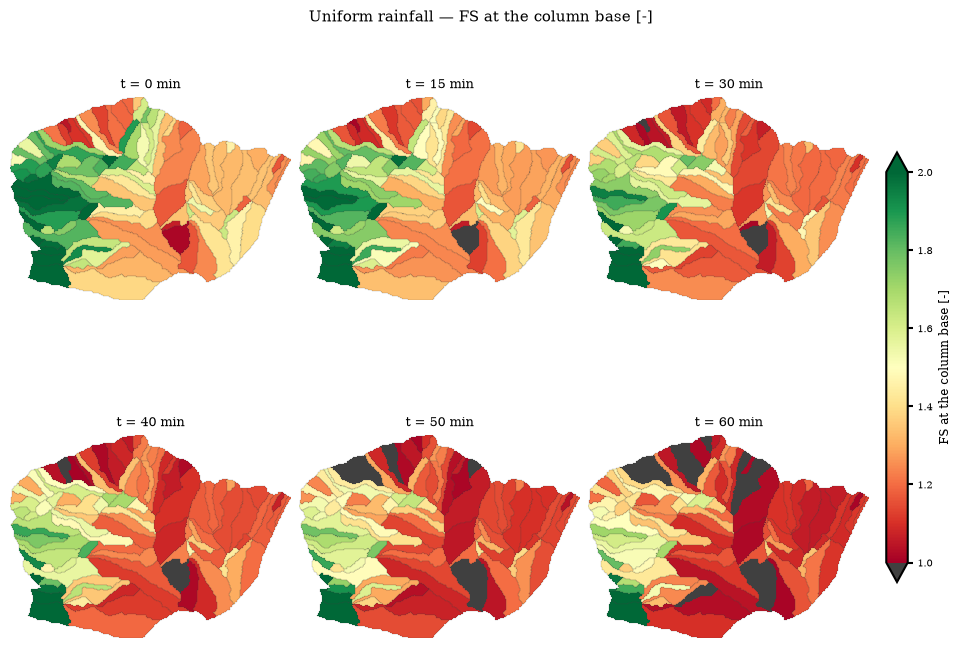

In [30]:
cmap = mpl.colormaps['RdYlGn']
cmap.set_under(color=".25")

plot_spatial_snapshots(
    "Uniform", "factor_of_safety_at_failure_plane", fs_norm, cmap,
    "FS at the column base [-]",
);


## Uniform rainfall: water-table rise

Each panel shows estimated rise relative to the initial water table at the column base. These are current values at the five output times, not maximum-rise summaries over the event.


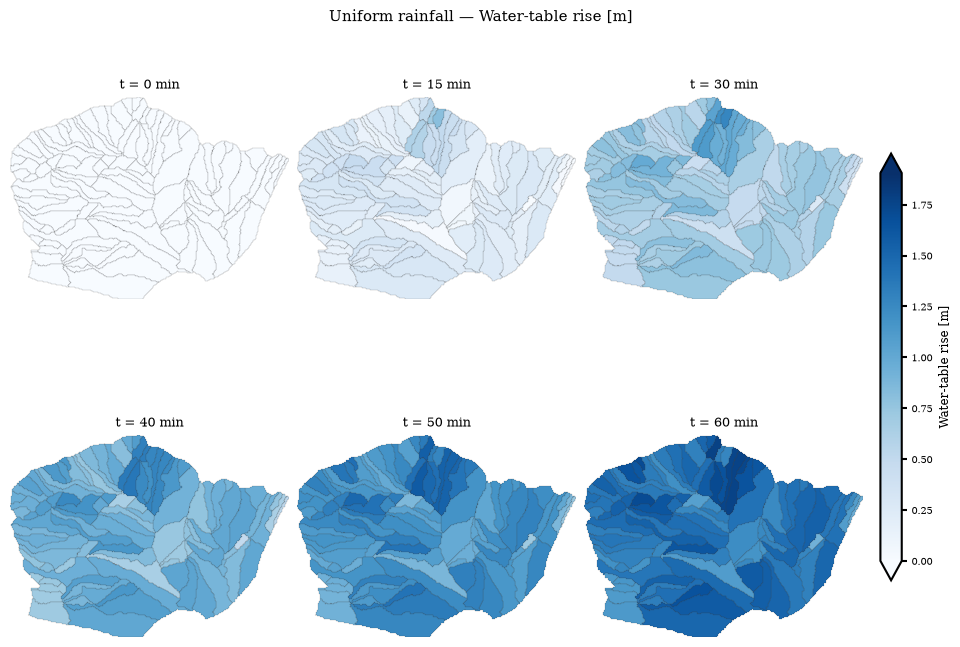

In [31]:
plot_spatial_snapshots(
    "Uniform", "water_table_rise", rise_norm, "Blues",
    "Water-table rise [m]",
);


## Nonconstant rainfall: factor of safety

Each panel shows base FS at its stated time. Values at or below 1 reach the deterministic stability threshold in this scenario, rather than an observed landslide or a failure probability.


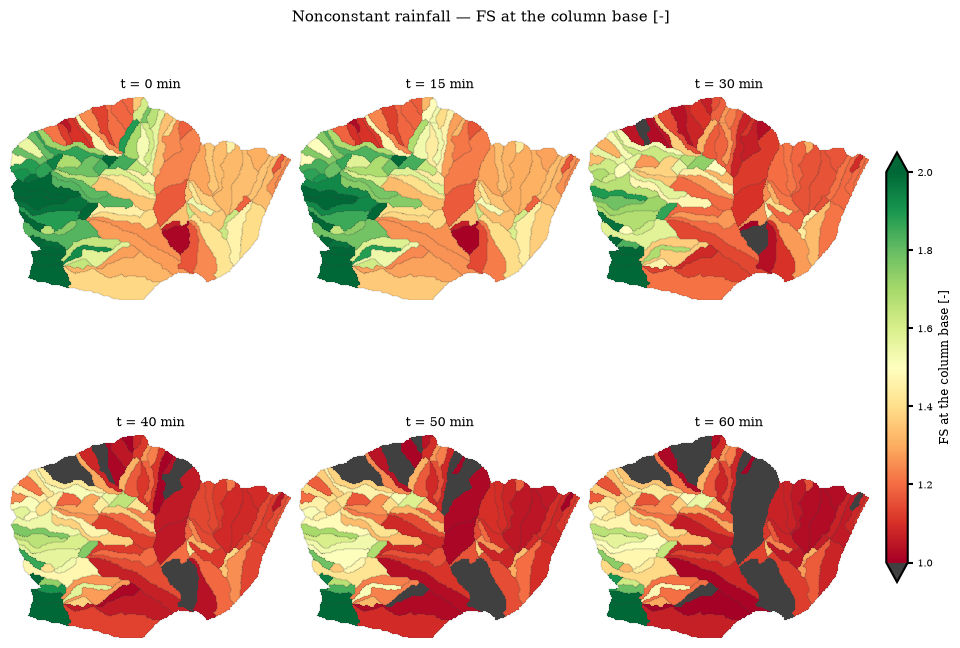

In [32]:
plot_spatial_snapshots(
    "Nonconstant", "factor_of_safety_at_failure_plane", fs_norm, cmap,
    "FS at the column base [-]",
);


## Nonconstant rainfall: water-table rise

Each panel shows estimated rise relative to the initial water table at the column base. These are current values at the five output times, not maximum-rise summaries over the event.


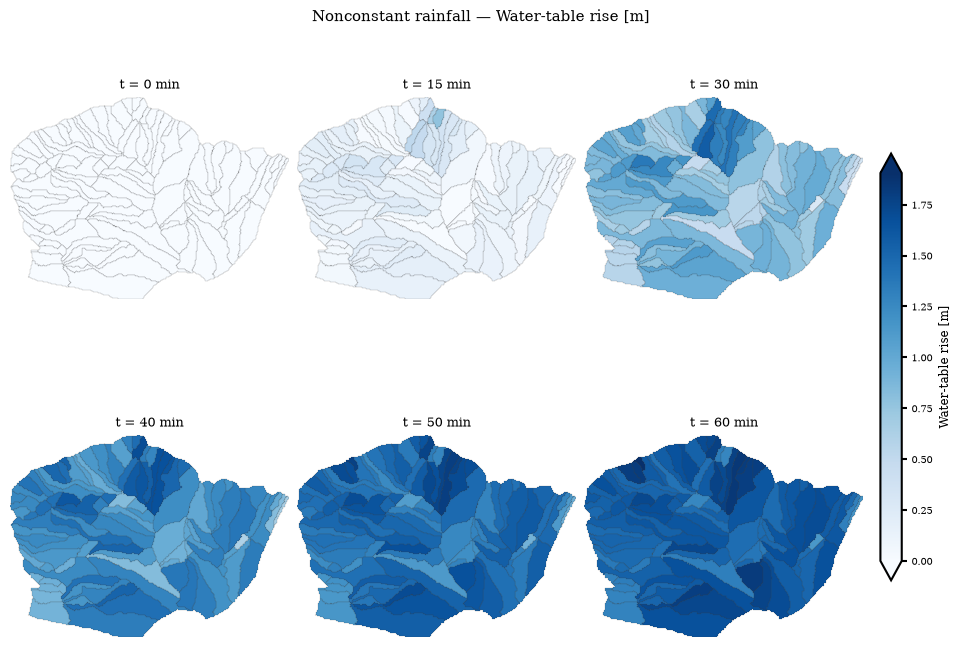

In [33]:
plot_spatial_snapshots(
    "Nonconstant", "water_table_rise", rise_norm, "Blues",
    "Water-table rise [m]",
);


## Interpret the two runs

Equal rainfall totals do not require equal responses. The nonconstant history supplies more water early in the hour, changing when water reaches the initial water table and how much is retained after drainage. Compare corresponding times using the common color scales. FS also depends on strength and geometry, so a larger rise does not by itself specify the stability threshold.

The following table separates units already at base FS ≤ 1 before rainfall from units first reaching that threshold in the sampled storm window. Each count refers to modeled base FS; full-column stability profiles are also available. The response after one hour is outside this comparison.

All 105 units start with base FS above 1; the minimum is 1.0135. At the five map times, the uniform history has 0, 1, 2, 8 and 15 units at base FS ≤ 1, compared with 0, 0, 3, 15 and 20 for the peaked history. The first sampled crossing is therefore at 15 minutes for uniform rainfall and 30 minutes for the peaked rainfall, although the latter affects more units by the end of the hour.

At 60 minutes, minimum base FS is 0.8459 for the uniform run and 0.8217 for the peaked run. Median water-table rise is 1.3991 m and 1.5661 m, respectively: the peaked run's median is approximately 0.167 m greater. Four units reach the surface water-table limit in both final snapshots; further rise is capped there by the reconstruction.

The early response helps interpret these differences. By 15 minutes the peaked history has supplied 22.5 mm, compared with 19.5 mm for uniform rain, yet its median rise is smaller: 0.1204 m versus 0.2330 m. Surface input and basal arrival are not simultaneous. By 30 minutes, the peaked history has supplied 61.5 mm versus 39 mm, and its median rise is larger: 0.8501 m versus 0.6747 m. The delayed transfer of the concentrated pulse explains why the lower late-hour rain rate does not immediately remove its effect.

These values apply to the current material properties, drainage setting, slopes and column depths. They are sampled base responses, not observed landslide counts or exact threshold times. The [pressure reconstruction](/unsatstab/fundamentals/#basal-and-pressure-assumptions) limits the physical interpretation, and the model may continue responding after rainfall stops. A longer output window is needed to assess post-storm extrema.

In [34]:
snapshot_rows = []
for name, simulation in spatial_results.items():
    initially_below = {unit_id for unit_id, result in simulation.columns.items()
                       if result.factor_of_safety_at_failure_plane[0] <= 1.0}
    for index, time in enumerate(output_times):
        below_now = {unit_id for unit_id, result in simulation.columns.items()
                     if result.factor_of_safety_at_failure_plane[index] <= 1.0}
        snapshot_rows.append({
            "History": name, "Time [min]": time * 60.0,  # convert hours to minutes
            "Units with base FS <= 1": len(below_now),
            "Initially at base FS <= 1": len(initially_below),
            "Initially stable, now base FS <= 1": len(below_now - initially_below),
            "Minimum base FS": min(r.factor_of_safety_at_failure_plane[index] for r in simulation.columns.values()),
            "Median water-table rise [m]": np.median([r.water_table_rise[index] for r in simulation.columns.values()]),
            "Water tables at surface": sum(np.isclose(r.water_table_depth[index], 0.0) for r in simulation.columns.values()),
        })
snapshot_table = pd.DataFrame(snapshot_rows)
display(snapshot_table.round(4))

,History,Time [min],Units with base FS <= 1,Initially at base FS <= 1,"Initially stable, now base FS <= 1",Minimum base FS,Median water-table rise [m],Water tables at surface
0,Uniform,0.0,0,0,0,1.0135,0.0000,0
1,Uniform,15.0,1,0,1,0.9913,0.2330,0
2,Uniform,30.0,2,0,2,0.9374,0.6747,1
3,Uniform,40.0,4,0,4,0.9047,0.9393,2
4,Uniform,50.0,10,0,10,0.8742,1.1804,4
5,Uniform,60.0,15,0,15,0.8459,1.3991,4
6,Nonconstant,0.0,0,0,0,1.0135,0.0000,0
7,Nonconstant,15.0,0,0,0,1.0069,0.1204,0
8,Nonconstant,30.0,3,0,3,0.9186,0.8501,3
9,Nonconstant,40.0,11,0,11,0.8660,1.2395,4


## Check the storage integration step

Repeat both histories with the same map times, roots and depth sampling, reducing only the storage step from one minute to 30 seconds. The reported differences are the largest absolute changes over all 105 units and the five output times. This checks storage integration for this experiment; it does not establish convergence of the root count, depth sampling, unsampled extrema or the physical reconstruction.

Halving the step changes the largest sampled rise by 0.489 mm in the uniform run and 0.460 mm in the peaked run. The largest absolute base-FS differences are approximately 0.000091 and 0.000086, with the same 15 and 20 units reaching the sampled threshold. A one-minute storage step is adequate for these reported outputs at the current root count and depth sampling.

In [35]:
refined_results = {
    name: us.run_slope_units(
        slope_units, materials, rainfall=forcing, output_times=output_times,
        equation_set="srivastava_yeh", n_roots=20, n_depths=24, n_jobs=2,
        storage_time_step=0.5 / 60.0,  # convert minutes to hours
    ) for name, forcing in rainfall_histories.items()
}
convergence_rows = []
for name, simulation in spatial_results.items():
    refined = refined_results[name]
    convergence_rows.append({
        "History": name,
        "Largest rise difference [m]": max(np.max(np.abs(r.water_table_rise - refined.result_for(unit_id).water_table_rise))
                                          for unit_id, r in simulation.columns.items()),
        "Largest base FS difference": max(np.max(np.abs(r.factor_of_safety_at_failure_plane - refined.result_for(unit_id).factor_of_safety_at_failure_plane))
                                           for unit_id, r in simulation.columns.items()),
        "Units with sampled base FS <= 1 (30 s)": int(refined.summary()["failure_plane_failed"].sum()),
    })
convergence_table = pd.DataFrame(convergence_rows)
display(convergence_table)

,History,Largest rise difference [m],Largest base FS difference,Units with sampled base FS <= 1 (30 s)
0,Uniform,0.000489,0.000091,15
1,Nonconstant,0.000460,0.000086,20


## Optional local property and rainfall overrides

Non-null optional SU columns override the mapped material; missing values inherit it. This small supplementary example changes the Gardner parameter and cohesion for one of two units, then assigns local two-interval rain histories. Both local histories supply 78 mm in one hour. One has 24 mm/h for 15 minutes followed by 96 mm/h for 45 minutes; the other reverses these two intervals. These settings illustrate configuration, not an isolated sensitivity experiment, because geometry and properties also differ.

See [spatial overrides and rainfall](/unsatstab/inputs-outputs/#spatially-varying-property-overrides) for precedence and column conventions.


In [36]:
example_units = slope_units.iloc[:2].copy()
example_units["alpha_m_inv"] = [np.nan, 0.6]
example_units["cohesion_pa"] = [np.nan, 7000.0]
example_units["int_0"], example_units["dur_0"] = [24.0, 96.0], [0.25, 0.75]
example_units["int_1"], example_units["dur_1"] = [96.0, 24.0], [0.75, 0.25]
amount_mm = (example_units["int_0"] * example_units["dur_0"]
             + example_units["int_1"] * example_units["dur_1"])
assert np.allclose(amount_mm, 78.0)
local_result = us.run_slope_units(
    example_units, materials, output_times=output_times,
    equation_set="srivastava_yeh", n_roots=20, n_depths=24, n_jobs=1,
    storage_time_step=1.0 / 60.0,  # convert minutes to hours
)
display(local_result.summary()[[
    "su_id", "minimum_factor_of_safety", "maximum_water_table_rise_m",
    "effective_initial_water_table_depth_m",
]])
# display the original results for comparison (only the first two units are shown)
display(spatial_results["Nonconstant"].summary()[[
    "su_id", "minimum_factor_of_safety", "maximum_water_table_rise_m",
    "effective_initial_water_table_depth_m",
]].iloc[:2])

,su_id,minimum_factor_of_safety,maximum_water_table_rise_m,effective_initial_water_table_depth_m
0,1,1.064248,1.530476,2.549533
1,2,0.897161,1.321194,3.063241


,su_id,minimum_factor_of_safety,maximum_water_table_rise_m,effective_initial_water_table_depth_m
0,1,1.025670,1.733831,2.549533
1,2,0.945249,1.708512,3.063241


## Loading columns with GIS names

GIS exports may use different field names. The mapping below associates each expected field with its source name; unlisted fields keep their usual names. It changes names only, so the [input units](/unsatstab/inputs-outputs/#column-names-from-gis-files) still apply. This two-unit check reuses the previous local-property and rainfall example and retains the GIS names in the summary.

In [37]:
column_mapping = {
    "su_id": "OBJECTID", "material_id": "MATERIAL",
    "slope_angle_deg": "SLOPE", "maximum_depth_m": "DEPTH",
    "initial_water_table_depth_m": "WT_DEPTH",
    "cohesion_pa": "COHESION", "int_0": "RAIN_1", "dur_0": "HOURS_1",
}
gis_units = example_units.rename(columns=column_mapping)
gis_result = us.run_slope_units(
    gis_units, materials, output_times=output_times, column_mapping=column_mapping,
    equation_set="srivastava_yeh", n_roots=20, n_depths=24, n_jobs=1,
    storage_time_step=1.0 / 60.0,  # convert minutes to hours
)
for unit_id in gis_units["OBJECTID"]:
    np.testing.assert_allclose(
        gis_result.result_for(unit_id).factor_of_safety_at_failure_plane,
        local_result.result_for(unit_id).factor_of_safety_at_failure_plane,
    )
assert gis_result.slope_units.crs == gis_units.crs
display(gis_result.summary()[[
    "OBJECTID", "MATERIAL", "minimum_factor_of_safety", "maximum_water_table_rise_m",
]])

,OBJECTID,MATERIAL,minimum_factor_of_safety,maximum_water_table_rise_m
0,1,n4n6-Hi,1.064248,1.530476
1,2,n4n6-Hi,0.897161,1.321194
